# Portfolio VaR, Expected Shortfall & Backtesting
### A Model Validation Case Study | GitHub Portfolio Walkthrough

**Research question.** How well do Historical Simulation, Gaussian Parametric, and Gaussian Monte Carlo methods forecast one-day-ahead portfolio tail losses, and how robust are the conclusions to alternative validation criteria?

**Scope:** Five-ETF fixed-weight portfolio (SPY, QQQ, IWM, EFA, EEM); 500-day rolling estimation windows; **3,732** common forecast dates from **2011-12-28 to 2026-10-30**; 95% and 99% VaR/ES.

**How to read this notebook.** This is a results-led guided tour—not a substitute for the source modules, six detailed research notebooks, or the full validation report. It loads saved CSV results and displays six research figures without rerunning costly Monte Carlo simulations.

**Key interpretation:** Historical Simulation attains the lowest *sample-average* FZ0 score at both levels. However, **none of six pairwise HAC tests remains significant after Holm correction** at the 5% family-wise threshold. VaR exceedances cluster across all models, and 99% unconditional coverage is rejected in the reported tests.

## 1. Research question and motivation

**Research question:** How reliably do different VaR and ES forecasting approaches measure one-day-ahead losses for a diversified ETF portfolio, and what do backtests reveal beyond a single exception rate?

- **VaR** identifies a loss threshold at a specified confidence level.
- **ES** describes average loss severity in the tail beyond the VaR threshold (under a continuous loss distribution; more generally, ES is the average of upper-tail quantiles).
- **Model validation** asks whether forecasts are calibrated, whether violations cluster, and whether joint VaR–ES predictions differ in predictive performance.

Passing an unconditional coverage test is *not* proof that a model is adequate: exceedances may cluster during turbulent periods. A smaller average forecast score is not necessarily a statistically significant improvement.

## 2. Reproducible project setup

This notebook assumes it sits alongside `src/`, `data/`, and `results/` in the repository root. If a result file is absent, the relevant cell explains what is missing instead of fabricating a value.

**Main repository components**

| Location | Role |
|---|---|
| `src/` | Data preparation, portfolio construction, risk model functions, backtesting tests |
| `run_phase1.py` | Data acquisition / Phase 1 pipeline |
| `notebooks/02_...` through `07_...` | Detailed modeling, backtesting, visualization and audit work |
| `run_backtesting.py` | Recomputes coverage, FZ0 and HAC/Holm summaries from forecast CSVs |
| `results/` | Model forecasts, summary tables and six figure files |
| `tests/` | Automated unit and integration tests |

To run the existing checks from a terminal: `python -m pytest tests/ -v`. The previously reported test run passed 72 tests; this notebook does not re-run them automatically.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Open this notebook from the project root (or notebooks/ directory)."
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
print("Project root:", ROOT)
print("Results folder:", RESULTS)

Project root: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting
Results folder: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting/results


## 3. Portfolio and data design

The portfolio uses five broad equity ETFs with **fixed target weights** (not an optimized portfolio). The specification used in `src/config.py` is:

| ETF | Weight | Exposure proxy |
|---|---:|---|
| SPY | 40% | U.S. large-cap equities |
| QQQ | 25% | Nasdaq-100 equities |
| IWM | 15% | U.S. small-cap equities |
| EFA | 10% | Developed-market equities outside the U.S. and Canada |
| EEM | 10% | Emerging-market equities |

Portfolio daily return is calculated as $r_{p,t}=\sum_i w_i r_{i,t}$. Forecast losses use **decimal return units**, $L_t=-r_{p,t}$, not dollar P&L. The configuration requests price history starting 2010-01-01 and ending before 2026-10-31, with a **500-trading-day rolling estimation window**. Check the processed files for realized sample dates.

**Important:** the portfolio weighting/rebalancing convention and adjusted-price handling should be described precisely using `src/portfolio.py` and `src/data_loader.py`; they are not independently established in this overview.

In [2]:
weights = pd.Series({"SPY": 0.40, "QQQ": 0.25, "IWM": 0.15, "EFA": 0.10, "EEM": 0.10}, name="Weight")
display(weights.to_frame().style.format({"Weight": "{:.0%}"}))
portfolio_path = ROOT / "data" / "processed" / "portfolio_returns.csv"
if portfolio_path.exists():
    portfolio_data = pd.read_csv(portfolio_path)
    print(f"Processed portfolio return rows: {len(portfolio_data):,}")
    display(portfolio_data.head(3))
else:
    print("Processed portfolio returns CSV not found; run the data pipeline if needed.")

,Weight
SPY,40%
QQQ,25%
IWM,15%
EFA,10%
EEM,10%


Processed portfolio return rows: 4,232


,Date,portfolio_return,realized_pnl_usd,realized_loss_usd,wealth_index,cumulative_return
0,2010-01-05,0.001357,1357.130955,-1357.130955,1.001357,0.001357
1,2010-01-06,-0.000736,-735.656880,735.656880,1.000620,0.000620
2,2010-01-07,0.001992,1991.948855,-1991.948855,1.002614,0.002614


## 4. Three risk forecasting approaches

### 4.1 Historical Simulation
A nonparametric estimate based on the observed distribution of returns in the historical estimation window. VaR is derived from the empirical return quantile; ES uses a **fractional-tail** average of the worst observations. This retains past empirical tail behavior but cannot anticipate unseen loss regimes.

### 4.2 Gaussian Parametric
Assume portfolio return $R_{p,t+1}\mid\mathcal F_t\sim N(\mu_t,\sigma_t^2)$, estimated on past returns. For confidence $c$ and $z_c=\Phi^{-1}(c)$:

$$\widehat{VaR}_{c,t+1}=-\widehat\mu_t+z_c\widehat\sigma_t,$$
$$\widehat{ES}_{c,t+1}=-\widehat\mu_t+\widehat\sigma_t\frac{\phi(z_c)}{1-c}.$$

The Gaussian assumption offers a transparent benchmark but may be too restrictive in periods of heavy-tailed market losses.

### 4.3 Gaussian Monte Carlo
Estimate the historical asset mean vector and covariance matrix, simulate multivariate normally distributed asset returns, apply the fixed portfolio weights, and extract simulation-based VaR / fractional-tail ES.

**Key interpretation:** Gaussian Parametric and Gaussian Monte Carlo share the same distributional assumptions. Any difference is not evidence that Monte Carlo captures fat tails; it can arise from simulation approximation and implementation choices.

## 5. Rolling out-of-sample design

For the forecast **evaluated at date $t$**, the intended estimation sample consists of the prior **500** observed daily returns (through date $t-1$). The realized return at $t$ is used only to evaluate that forecast. The three saved model files share 3,732 evaluation dates, from 2011-12-28 to 2026-10-30.

> **Validation boundary:** Agreement in date ranges and realized returns across forecast CSVs is verified below. This overview does **not independently prove** that the upstream notebook loops excluded the evaluation-day return; that requires a separate audit of the forecast-generation code.

- **Target:** one-day-ahead loss measured in decimal return units (figures convert to percent).
- **Estimation:** 500-observation rolling history.
- **Evaluation:** 95% and 99% thresholds on common dates and realized losses.

In [3]:
model_files = {
    "Historical": "historical_var_es_forecasts.csv",
    "Parametric": "parametric_var_es_forecasts.csv",
    "Monte Carlo": "monte_carlo_var_es_forecasts.csv",
}
models = {}
for name, filename in model_files.items():
    path = RESULTS / filename
    if path.exists():
        models[name] = pd.read_csv(path, parse_dates=["Date"])
    else:
        print(f"Missing forecast file: {path}")
if models:
    overview = pd.DataFrame([
        {"Model": name, "Forecasts": len(df), "First date": df["Date"].min().date(),
         "Last date": df["Date"].max().date(), "Unique dates": df["Date"].is_unique}
        for name, df in models.items()
    ])
    display(overview)
    if len(models) == 3:
        dates_match = all(df["Date"].equals(models["Historical"]["Date"]) for df in models.values())
        returns_match = all(np.allclose(df["actual_return"], models["Historical"]["actual_return"], rtol=0, atol=1e-10)
                            for df in models.values())
        print("Aligned dates:", dates_match, "| Aligned realized returns:", returns_match)
else:
    print("No saved forecast files found.")

,Model,Forecasts,First date,Last date,Unique dates
0,Historical,3732,2011-12-28,2026-10-30,True
1,Parametric,3732,2011-12-28,2026-10-30,True
2,Monte Carlo,3732,2011-12-28,2026-10-30,True


Aligned dates: True | Aligned realized returns: True


## 6. VaR exceedance backtesting

A one-day VaR exception is defined as $I_t=\mathbf{1}\{L_t>\widehat{VaR}_t\}$ with realized loss $L_t=-r_t$.

- **Kupiec unconditional coverage (POF):** tests whether the *overall exception frequency* equals 5% or 1%.
- **Christoffersen independence (IND):** tests whether a first-order exception indicator depends on its previous state.
- **Christoffersen conditional coverage (CC):** tests joint coverage and first-order independence.

**Observed exceptions (N = 3,732 for each row):**

| Model | 95% count (rate) | 99% count (rate) |
|---|---:|---:|
| Historical | 176 (4.72%) | 50 (1.34%) |
| Parametric | 181 (4.85%) | 83 (2.22%) |
| Monte Carlo | 181 (4.85%) | 85 (2.28%) |
| Nominal expectation | 186.6 (5.00%) | 37.32 (1.00%) |

**Interpretation:** At 95%, none of the models is rejected by the Kupiec POF test (p = 0.4217, 0.6726, 0.6726 respectively), but all fail the Christoffersen independence test (p < 0.001), revealing exception clustering. At 99%, all three are rejected by Kupiec POF at the unadjusted 5% level (Historical p = 0.04735; Parametric p ≈ 9.64×10⁻¹¹; Monte Carlo p ≈ 1.79×10⁻¹¹), and all fail independence and conditional coverage. **Failure to reject** at 95% does not establish a correctly specified model.

The next cell reads the actual `var_backtesting_summary.csv` for full LR statistics and exact p-values.

In [4]:
def show_csv(filename, sort_columns=None):
    path = RESULTS / filename
    if not path.exists():
        print(f"Not found: {path}")
        return None
    frame = pd.read_csv(path)
    display(frame)
    return frame

backtesting_summary = show_csv("var_backtesting_summary.csv")

,Model,Confidence,Observations,Exceptions,Exception_Rate,LR_POF,p_POF,LR_IND,p_IND,LR_CC,p_CC
0,Historical,95%,3732,176,0.047160,0.645541,4.217114e-01,15.766691,0.000072,16.406275,2.737932e-04
1,Historical,99%,3732,50,0.013398,3.932930,4.734938e-02,16.849326,0.000040,20.789136,3.059825e-05
2,Parametric,95%,3732,181,0.048499,0.178608,6.725727e-01,12.162165,0.000488,12.337630,2.093716e-03
3,Parametric,99%,3732,83,0.022240,41.892781,9.641793e-11,23.125778,0.000002,65.043447,7.516141e-15
4,Monte Carlo,95%,3732,181,0.048499,0.178608,6.725727e-01,12.162165,0.000488,12.337630,2.093716e-03
5,Monte Carlo,99%,3732,85,0.022776,45.188696,1.789349e-11,22.164614,0.000003,67.379295,2.337610e-15


## 7. Joint VaR–ES forecast quality: FZ0 scoring

Since standard VaR exceedance tests do not measure Expected Shortfall accuracy directly, we use the joint **FZ0** score (positive-loss and positive-ES convention):

$$S_t=\frac{VaR_t}{ES_t}+\log(ES_t)-1+\frac{\mathbf{1}\{L_t>VaR_t\}(L_t-VaR_t)}{(1-c)ES_t}.$$

*Lower mean scores indicate better sample-average joint VaR/ES performance under this scoring rule.*

| Model | Mean FZ0 at 95% | Mean FZ0 at 99% |
|---|---:|---:|
| **Historical** | **−3.620178** | **−3.045914** |
| Parametric | −3.572465 | −2.756745 |
| Monte Carlo | −3.572331 | −2.755703 |

Historical has the best *sample mean* at both confidence levels. This is a **descriptive comparison**, not itself a finding of statistically significant superiority. Note that Gaussian Monte Carlo and Gaussian Parametric share a normality assumption; Monte Carlo introduces numerical simulation, not an independent heavy-tail model.

In [5]:
fz_summary = show_csv("fz0_score_summary.csv")

,Model,Confidence,Observations,Mean_FZ0,Std_FZ0
0,Historical,95%,3732,-3.620178,2.646071
1,Historical,99%,3732,-3.045914,5.453462
2,Parametric,95%,3732,-3.572465,3.310901
3,Parametric,99%,3732,-2.756745,9.779116
4,Monte Carlo,95%,3732,-3.572331,3.309051
5,Monte Carlo,99%,3732,-2.755703,9.775340


## 8. Model comparisons: HAC inference and Holm multiplicity correction

We compare daily paired FZ0 scores via $d_t=S_{B,t}-S_{A,t}$. A **positive** mean difference means Model A has the lower (better) score. An intercept-only model with HAC covariance (`maxlags=10`) tests the mean difference; **Holm correction** then controls family-wise error across the six comparisons (three pairs × two confidence levels).

| Confidence | A vs B | Mean difference (B − A) | Raw HAC p | Holm-adjusted p | Reject after Holm? |
|---|---|---:|---:|---:|---|
| 95% | Historical vs Parametric | +0.047713 | 0.015213 | 0.087400 | No |
| 95% | Historical vs Monte Carlo | +0.047847 | 0.014567 | 0.087400 | No |
| 95% | Parametric vs Monte Carlo | +0.000134 | 0.741278 | 0.996415 | No |
| 99% | Historical vs Parametric | +0.289168 | 0.019491 | 0.087400 | No |
| 99% | Historical vs Monte Carlo | +0.290211 | 0.019033 | 0.087400 | No |
| 99% | Parametric vs Monte Carlo | +0.001042 | 0.498207 | 0.996415 | No |

**Inference:** Four Historical-vs-Gaussian comparisons have raw p < 0.05, yet **none survives Holm adjustment at 0.05**. Therefore, report Historical's favorable scores as a descriptive advantage with *insufficient multiplicity-adjusted evidence of pairwise superiority*. The model's HAC output column is named `t_stat`, though the statsmodels robust p-values use its asymptotic reference distribution.

In [6]:
hac_summary = show_csv("hac_model_comparison.csv")

,Confidence,Model_A,Model_B,HAC_Lags,Observations,Mean_Difference,HAC_SE,t_stat,p_value,Holm_Adjusted_p,Reject_After_Holm
0,95%,Historical,Parametric,10,3732,0.047713,0.019657,2.427276,0.015213,0.087400,False
1,95%,Historical,Monte Carlo,10,3732,0.047847,0.019585,2.442977,0.014567,0.087400,False
2,95%,Parametric,Monte Carlo,10,3732,0.000134,0.000405,0.330161,0.741278,0.996415,False
3,99%,Historical,Parametric,10,3732,0.289168,0.123787,2.336009,0.019491,0.087400,False
4,99%,Historical,Monte Carlo,10,3732,0.290211,0.123763,2.344893,0.019033,0.087400,False
5,99%,Parametric,Monte Carlo,10,3732,0.001042,0.001539,0.677313,0.498207,0.996415,False


In [7]:
# Reconcile the saved outputs with the research summary (no model re-estimation).
if backtesting_summary is not None and fz_summary is not None and hac_summary is not None:
    assert len(backtesting_summary) == 6
    assert len(fz_summary) == 6
    assert len(hac_summary) == 6
    assert set(backtesting_summary["Observations"]) == {3732}
    assert set(fz_summary["Observations"]) == {3732}
    assert set(hac_summary["Observations"]) == {3732}
    assert not hac_summary["Reject_After_Holm"].astype(str).str.lower().eq("true").any()
    print("Summary tables align with the reported sample size and Holm decisions.")
else:
    print("Place the notebook in the project root to load and verify local CSV outputs.")

Summary tables align with the reported sample size and Holm decisions.


## 9. Figures: dynamics, stress episodes, and stability

The next cell displays the six existing research figures directly from `results/figures/`:

1. **Full-sample 99% VaR (Figure 1A)** — daily loss versus model thresholds, with Historical exceedances marked in red.
2. **Alternative full-sample VaR view** — similar information, useful as a supplementary figure rather than a separate empirical claim.
3. **2020 crisis zoom** — extreme losses initially exceed thresholds; risk estimates react as observations enter their 500-day rolling samples. The graph documents realized exceedances, but cannot alone establish timing-correct forecasts.
4. **Observed versus nominal exception rates** — near-5% rates at 95%, versus higher-than-1% rates at 99%.
5. **Annual FZ0 score differences** — Parametric−Historical and Monte Carlo−Historical vary in sign across years; positive values mean Historical performed better on that year's average score. Annual point estimates are **not** annual significance tests.
6. **Year exclusion sensitivity** — Historical's full-sample mean advantage shrinks substantially when 2018 and 2020 are excluded. This is a **descriptive sensitivity check**, not a re-estimated Holm-adjusted hypothesis test.

**Presentation choice:** Figures 1 and 2 partly duplicate the full-sample comparison. In a concise report, keep one in the main text and move the other to an appendix.

### Figure 1 — Full sample: rolling 99% VaR

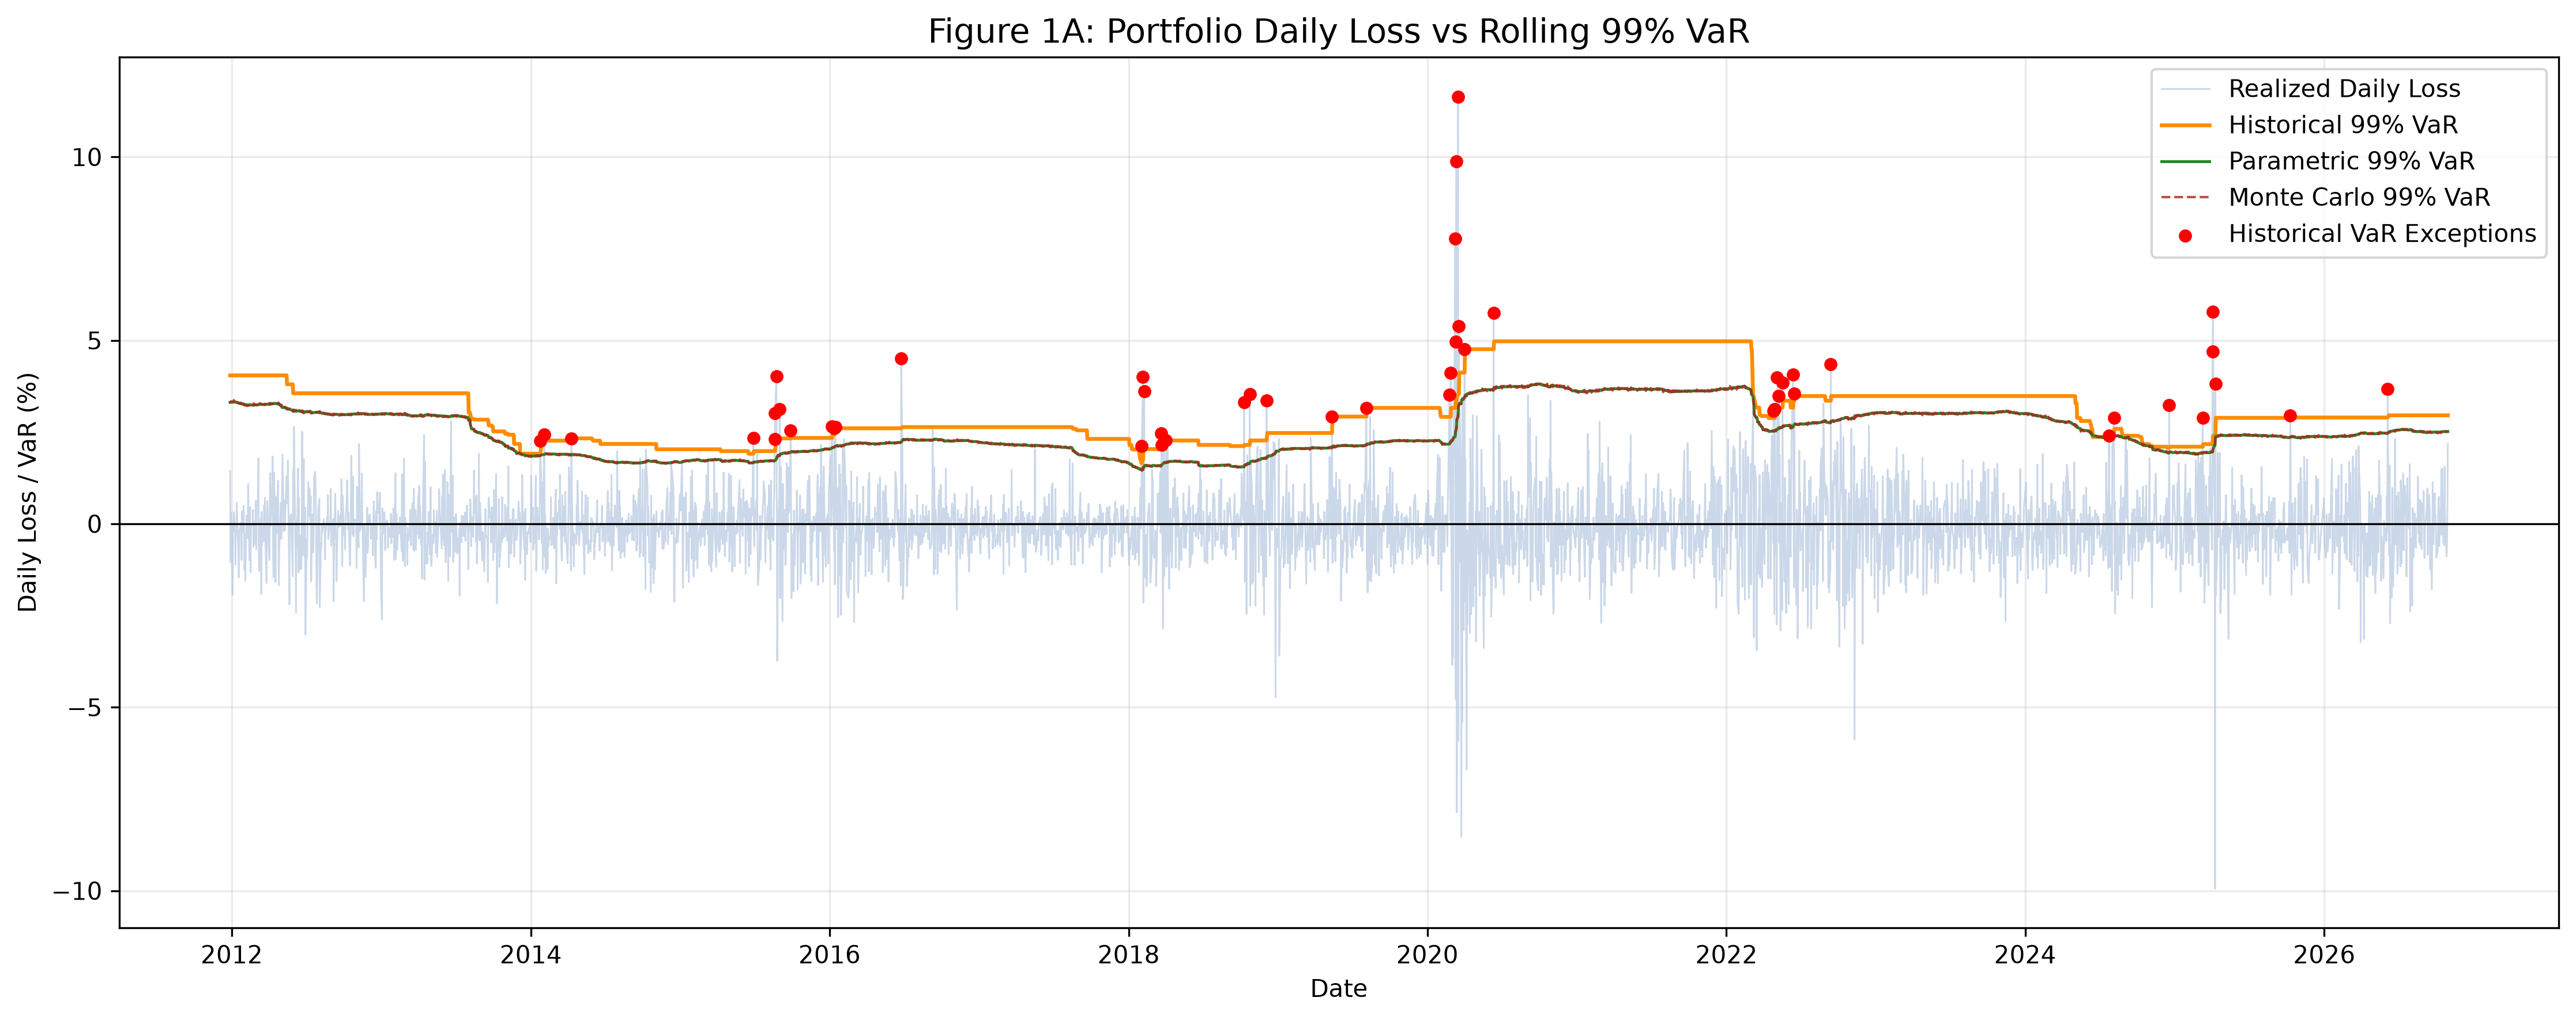

### Figure 2 — Forecast VaR vs. realized loss

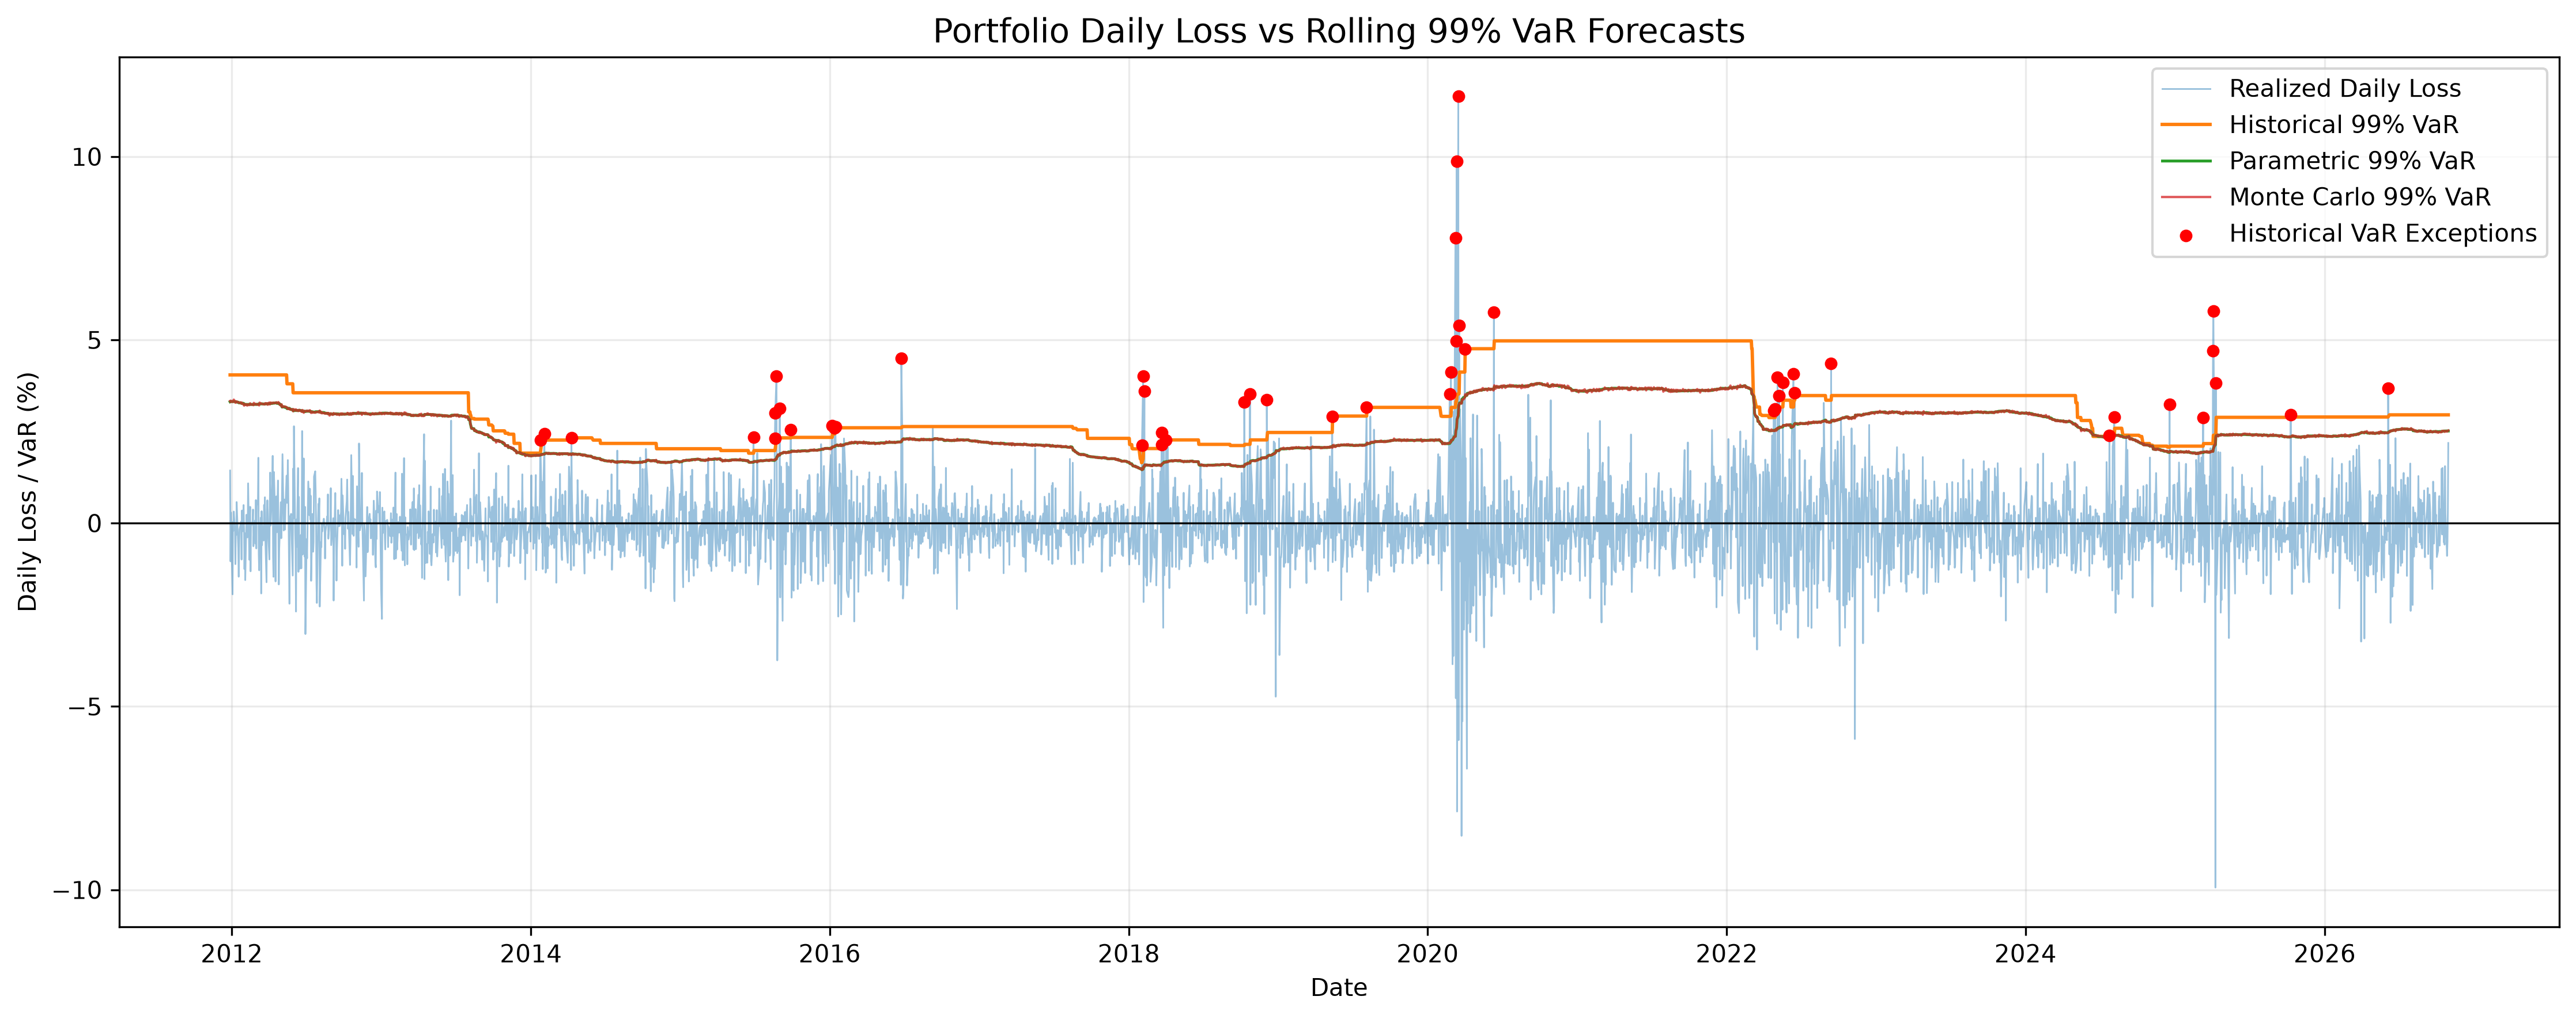

### Figure 3 — Stress-period detail (2020)

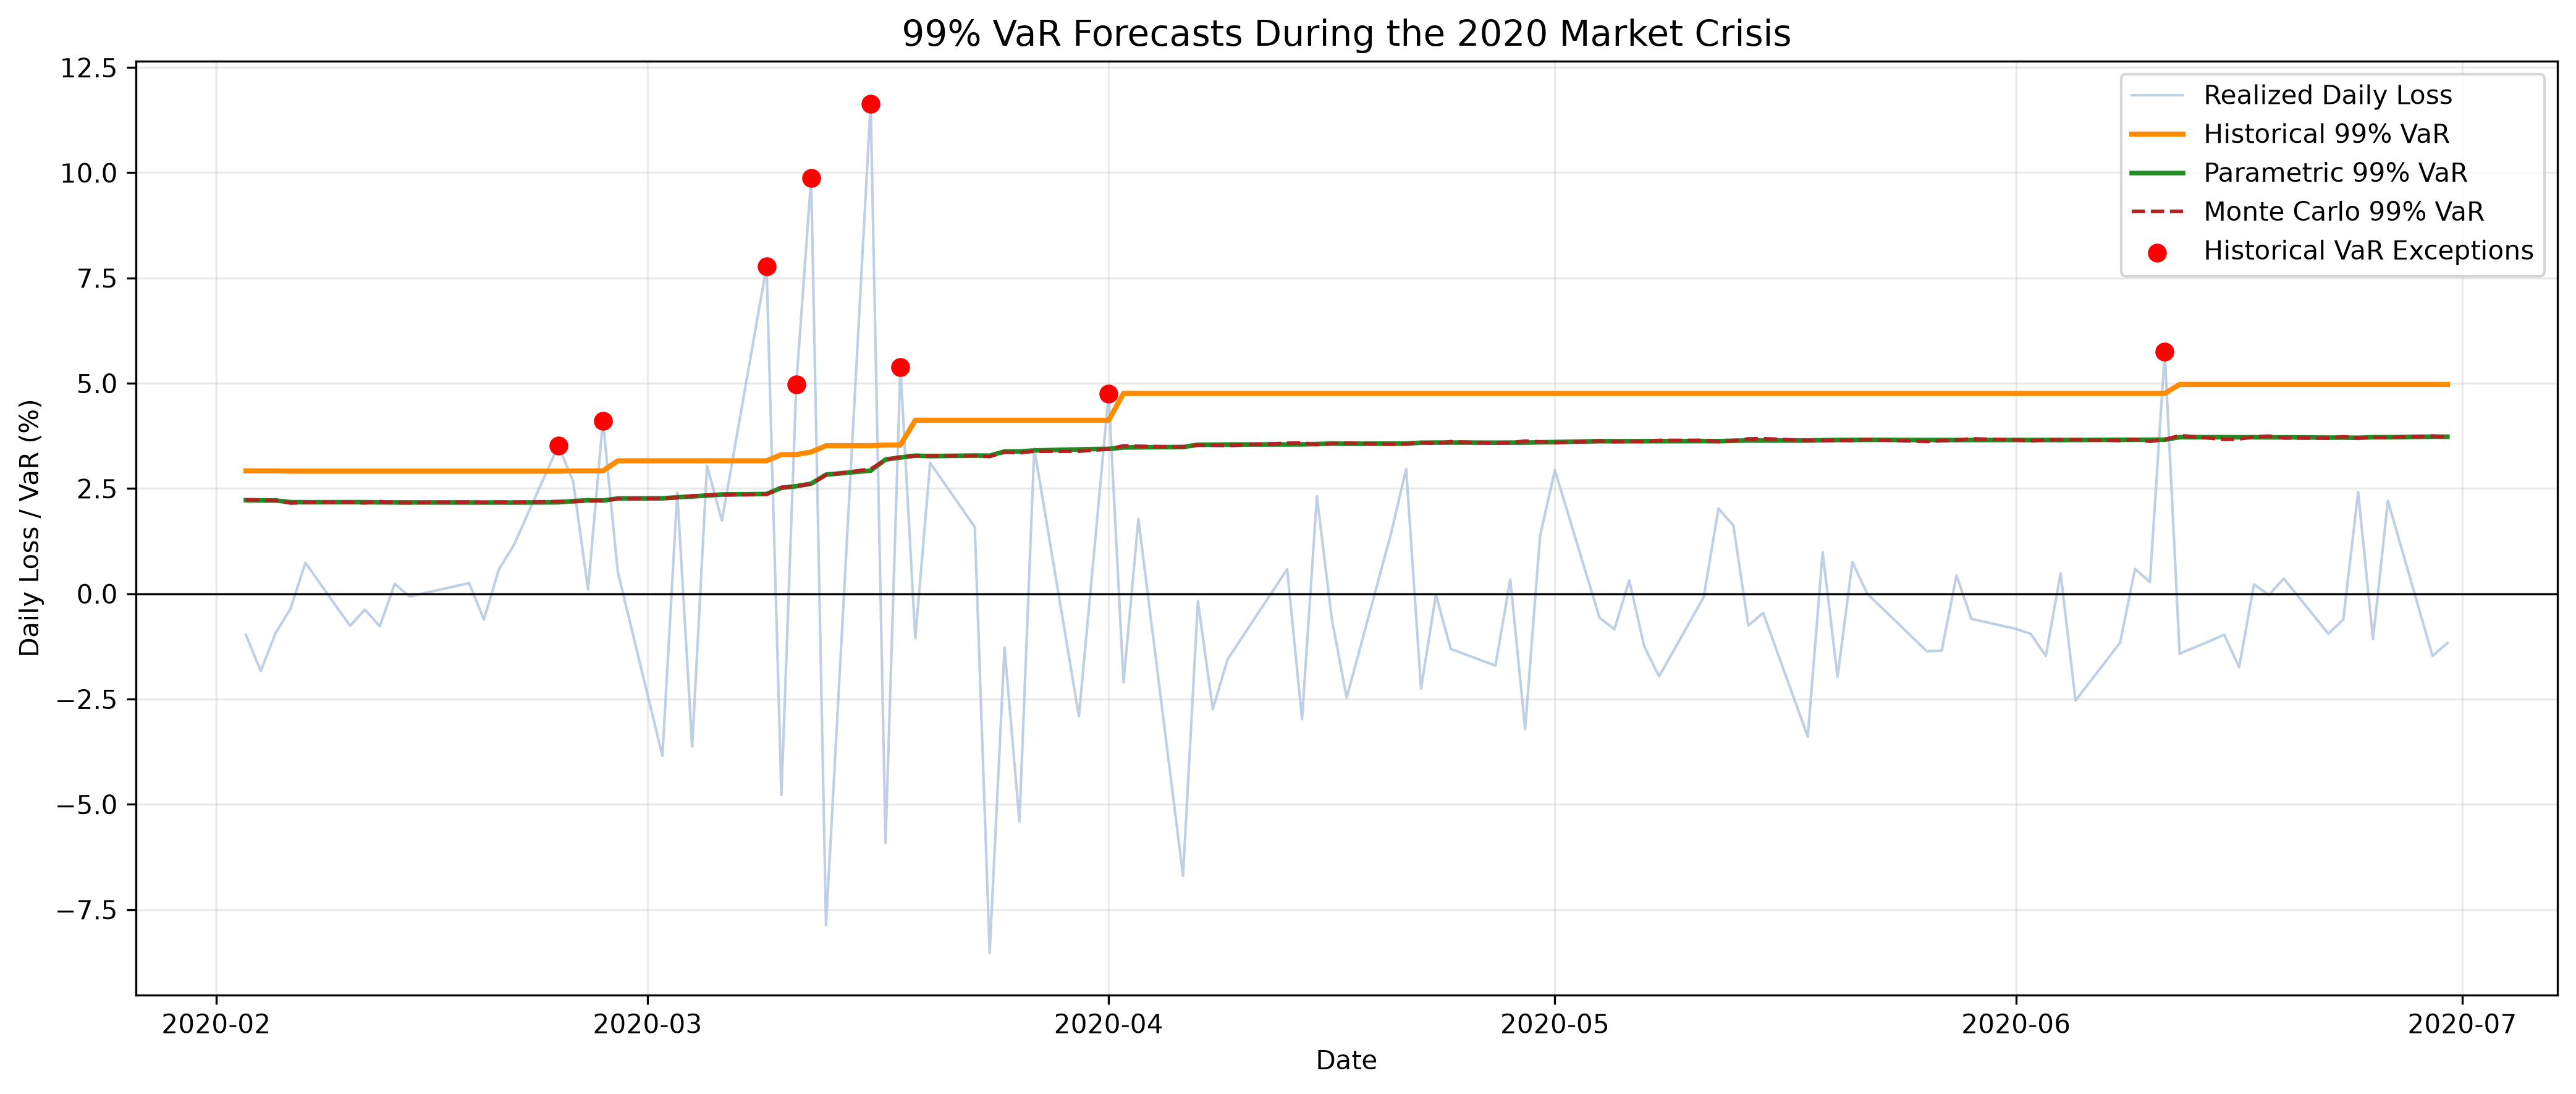

### Figure 4 — VaR exception rates

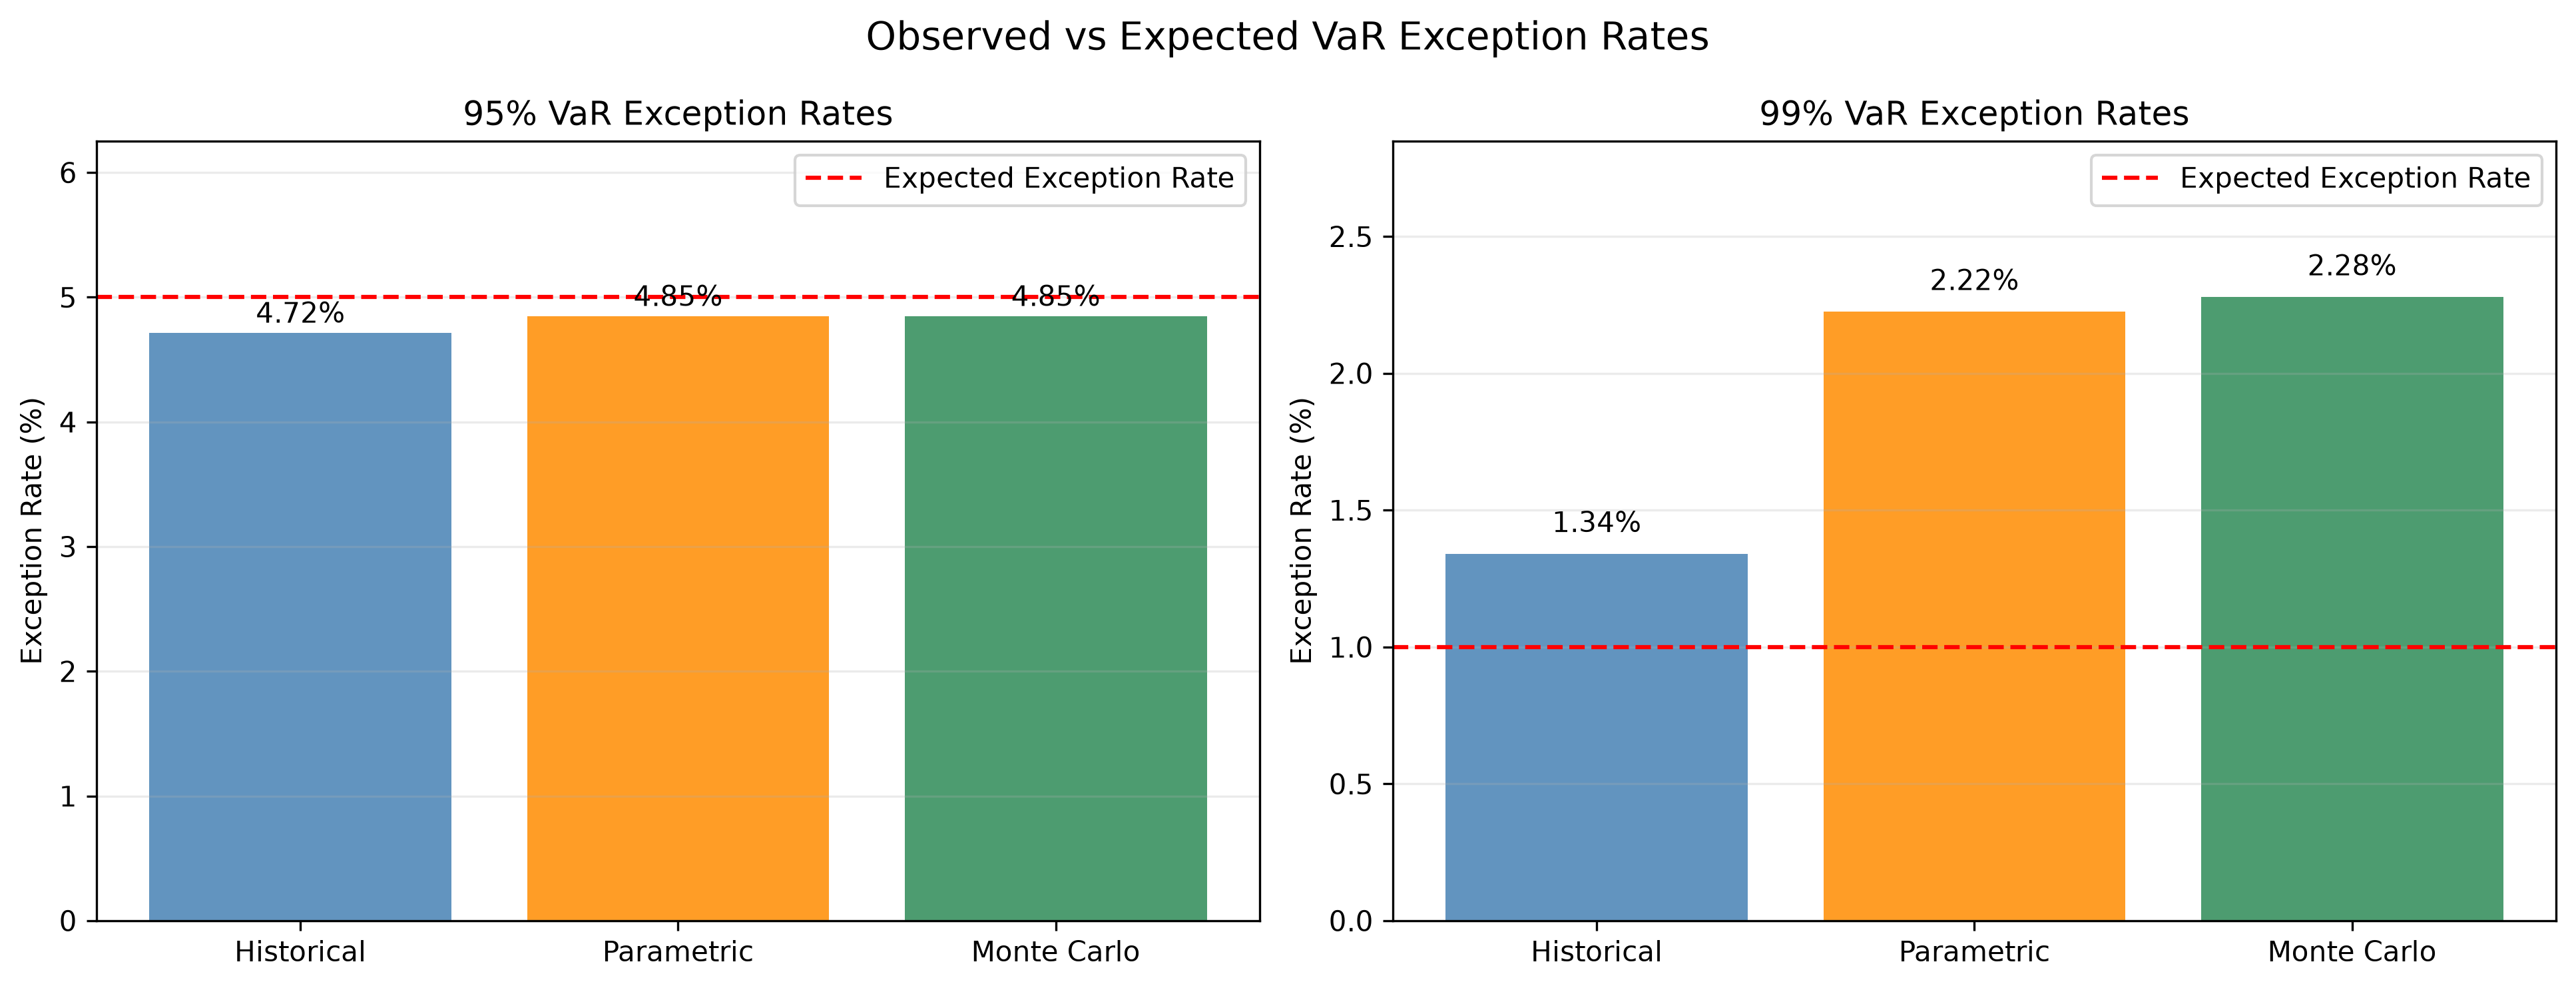

### Figure 5 — Annual FZ0 differences

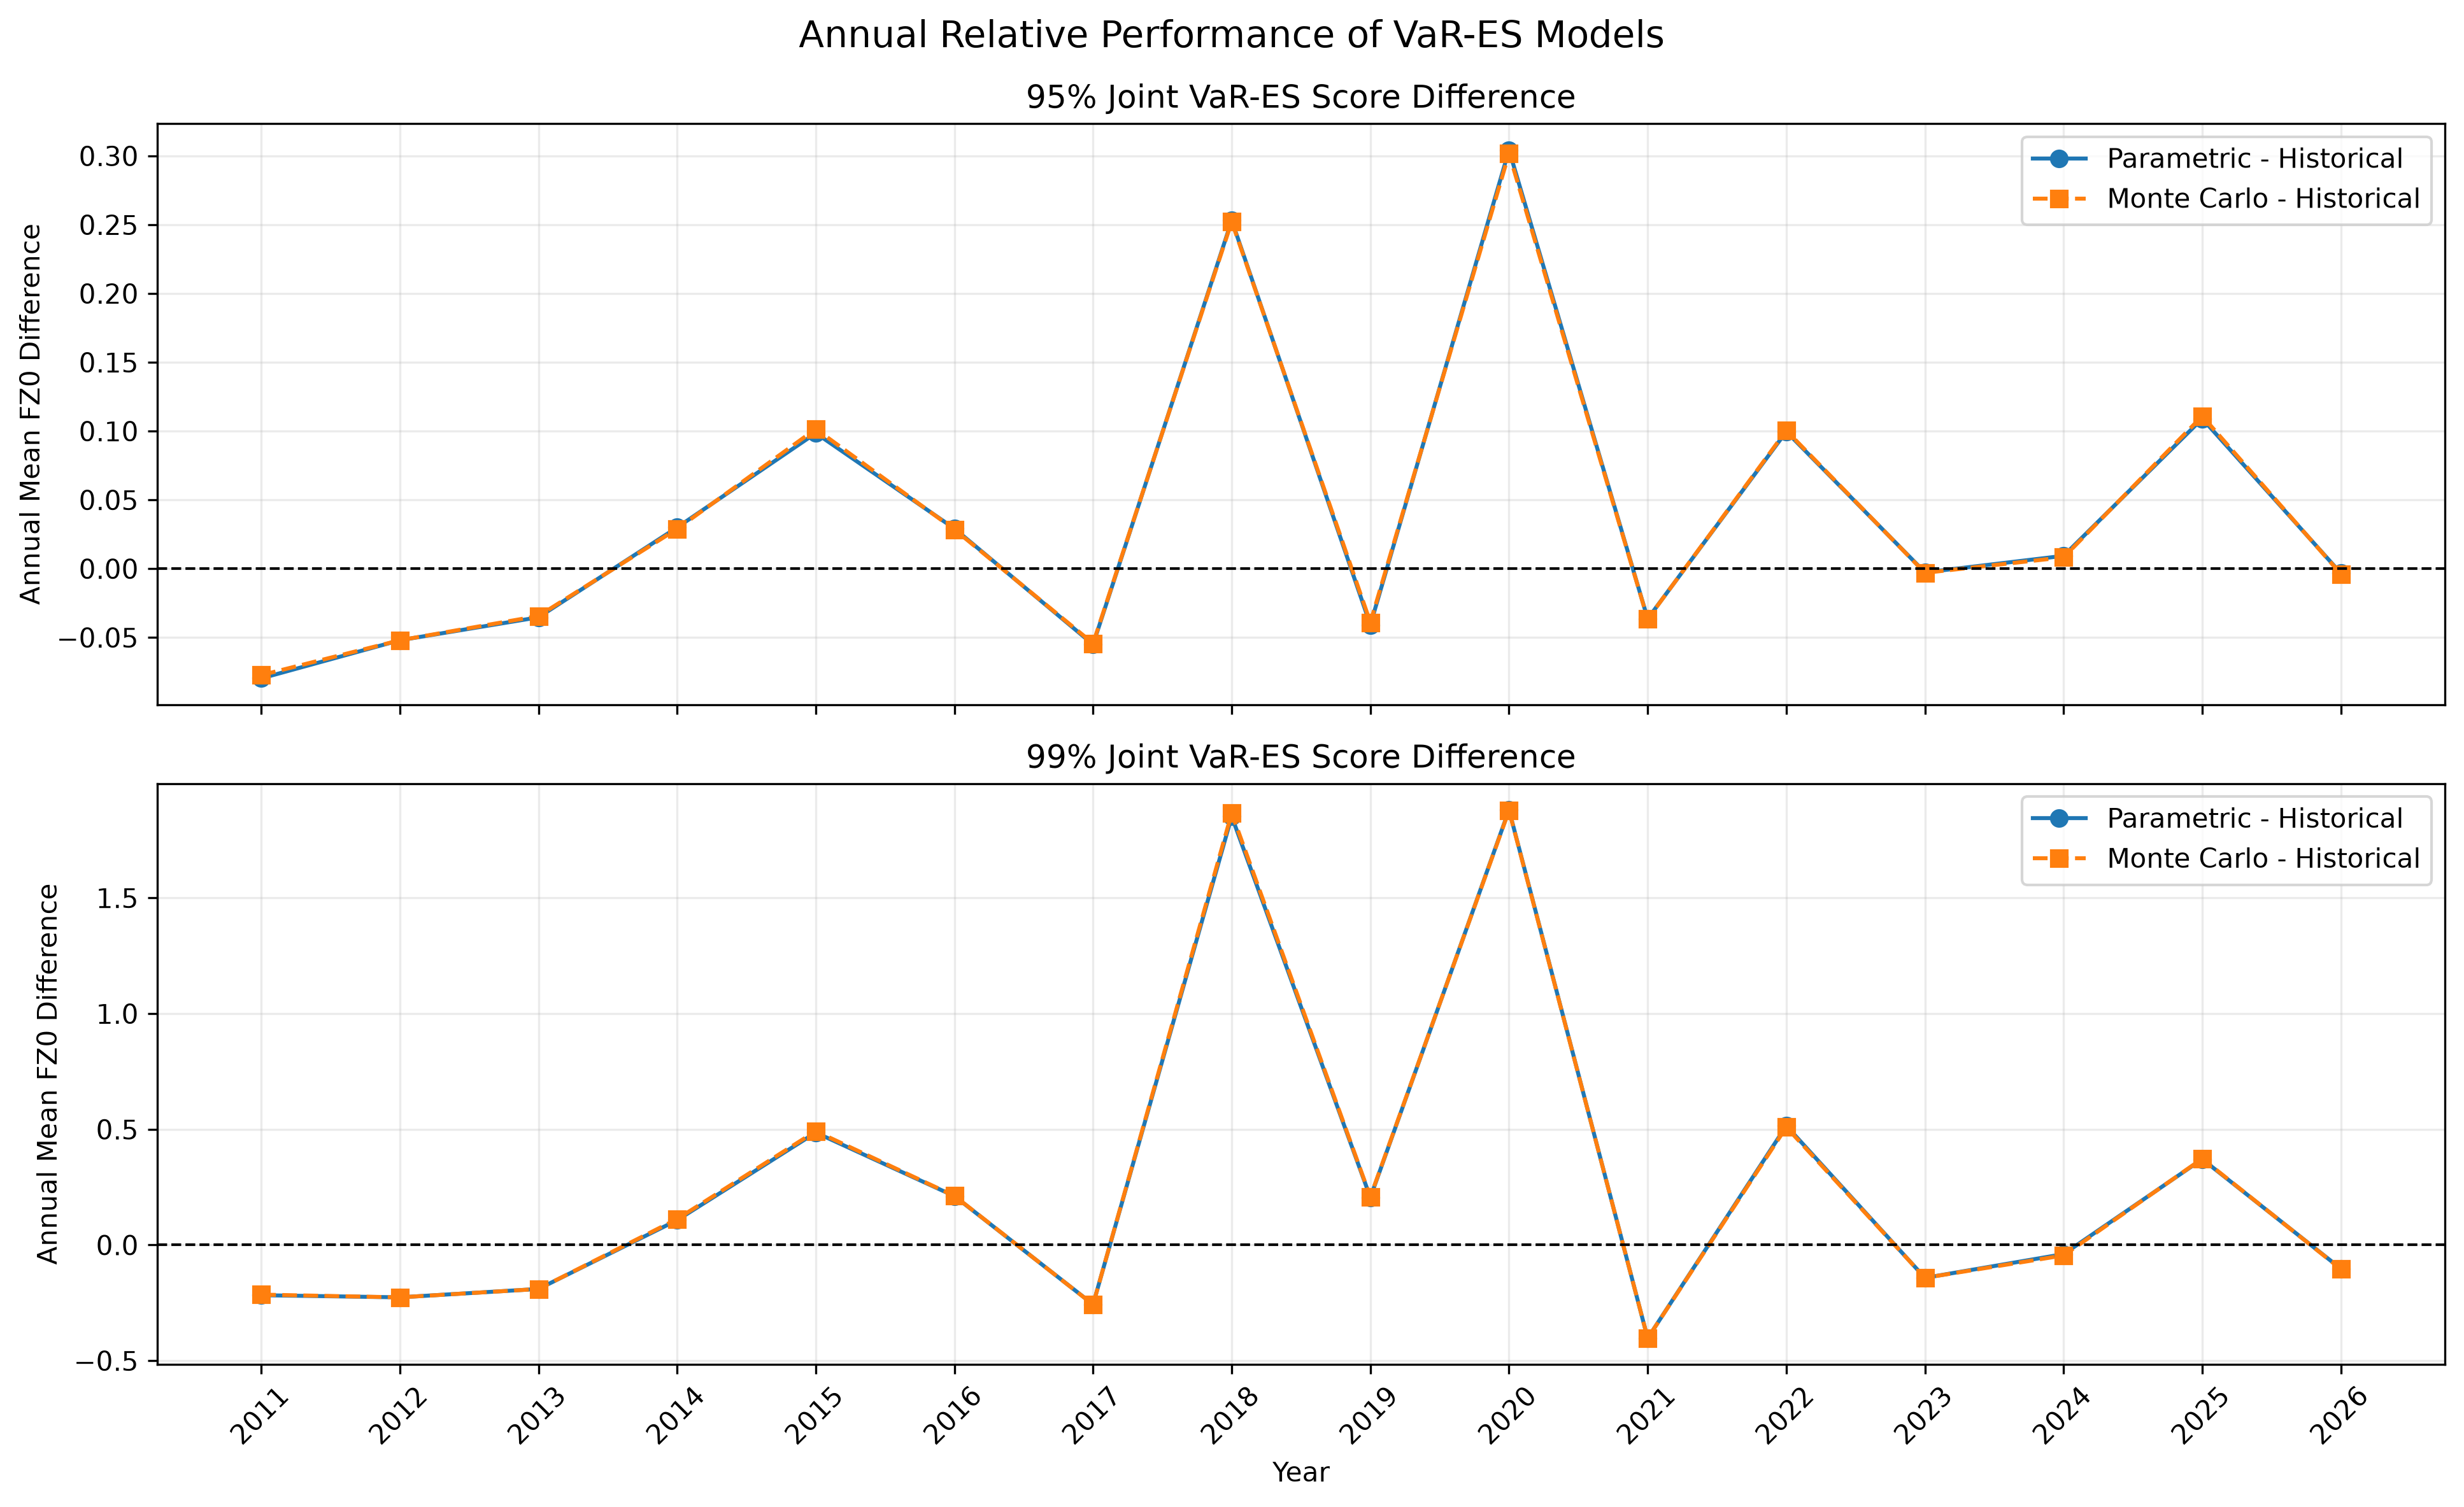

### Figure 6 — FZ0 exclusion robustness

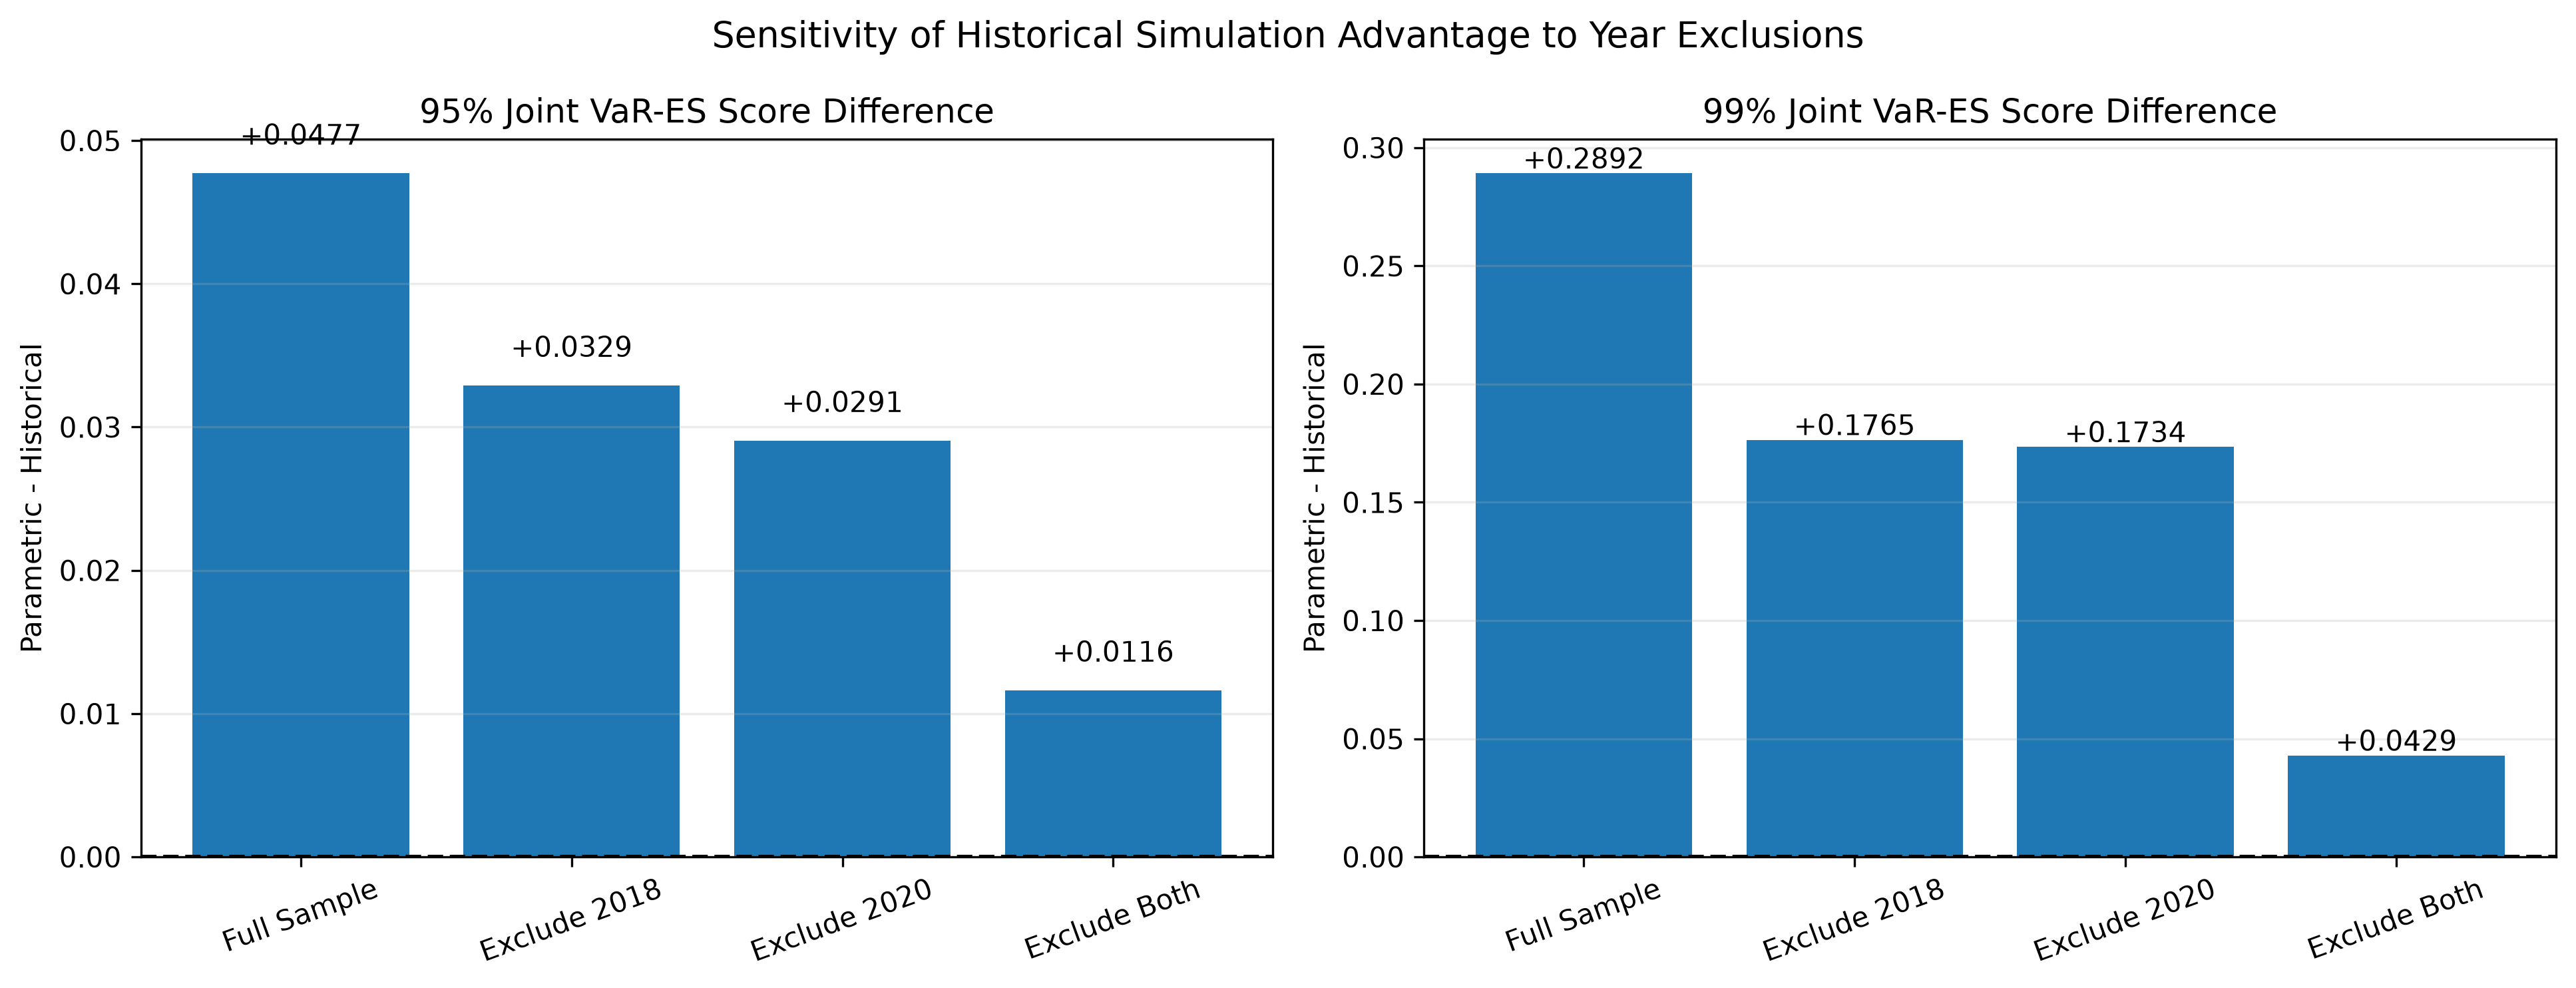

In [8]:
figure_specs = [
    ("rolling_var_99_full_sample.png", "Figure 1 — Full sample: rolling 99% VaR"),
    ("rolling_var_99_vs_realized_loss.png", "Figure 2 — Forecast VaR vs. realized loss"),
    ("var_99_2020_crisis_zoom.png", "Figure 3 — Stress-period detail (2020)"),
    ("var_exception_rates.png", "Figure 4 — VaR exception rates"),
    ("annual_fz0_score_differences.png", "Figure 5 — Annual FZ0 differences"),
    ("fz0_exclusion_robustness.png", "Figure 6 — FZ0 exclusion robustness"),
]
for filename, heading in figure_specs:
    display(Markdown(f"### {heading}"))
    path = FIGURES / filename
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Not found: {path}")

## 10. Evidence-based findings and stress-period interpretation

**Finding A — Adequate unconditional coverage at 95% does not imply independent exceptions.** The POF tests do not reject any model at 95%, whereas all independence and conditional coverage tests reject at 5%. The frequency of losses beyond VaR is therefore not the only model validation concern.

**Finding B — All models fail 99% unconditional coverage in the supplied full-sample tests.** Historical registers 50 exceptions (1.34%), compared with 83 (2.22%) for Parametric and 85 (2.28%) for Monte Carlo; each exceeds the nominal 1% rate. Historical's 99% POF p-value (0.04735) is relatively borderline at 5%; it must not be presented as strong evidence comparable to the Gaussian models' much smaller p-values.

**Finding C — Historical has the lowest sample-average joint VaR–ES score, but not a Holm-significant lead.** Raw HAC p-values favor Historical over each Gaussian alternative at both confidence levels. After six-way Holm correction, the adjusted p-value is 0.0874 for all four such comparisons, above 0.05.

**Finding D — Performance varies by year and episode.** Annual FZ0 score differences reverse sign in multiple years. In the exclusion analysis, the Parametric-minus-Historical gap changes from +0.0477 (full sample) to +0.0116 (exclude 2018 and 2020) at 95%, and from +0.2892 to +0.0429 at 99%. The remaining positive gaps do not by themselves establish statistical significance.

**Finding E — The two Gaussian methodologies are nearly equivalent in this setting.** Their 95% VaR exception counts are identical (181); at 99% they are 83 and 85. Their score gaps are very small and their pairwise HAC comparisons are not statistically significant. This is consistent with their shared Gaussian assumption.

### Overall model-risk judgment
No method has passed every diagnostic. Historical is the strongest *descriptive* performer in sample under FZ0 but still fails independence and 99% coverage tests. The evidence supports monitoring model assumptions, stress-period adaptation, and exception clustering rather than presenting a single model as definitively validated.

## 11. Model limitations and next research steps

- **Forecast information set:** Shared forecast dates, equal realized return series, and passing unit tests do not independently establish that every 500-day estimation window excluded the future evaluation-day return. The source forecasting loops should be audited before claiming leakage-free production readiness.
- **Distributional risk:** Gaussian Parametric and Gaussian Monte Carlo both rely on multivariate normal daily returns and may underestimate extreme losses; simulation does not remove this assumption.
- **Historical Simulation risk:** The historical tail depends on past observations, the 500-day estimation length, and the choice of empirical quantile/ES convention. Extreme episodes can enter and eventually leave the window.
- **Dependence:** All models exhibit evidence against independent exceedances under the reported first-order tests.
- **Multiple comparisons:** Nominal HAC significance does not survive the six-comparison Holm correction; no adjusted claim of model superiority is warranted at 5%.
- **Temporal heterogeneity:** Full-sample FZ0 differences partly reflect 2018/2020; annual score differences and year-exclusion bars are descriptive, not formal proof of regime-specific superiority.
- **Inference choices:** HAC bandwidth of ten trading days, the limited number of extreme 99% exceptions, and alternative test specifications should be assessed in sensitivity studies.

**Future extensions:** fat-tailed parametric distributions (e.g., Student-t), filtered historical simulation, EWMA/GARCH volatility dynamics, rolling-window and HAC-lag sensitivity, and direct stress/scenario analysis. These are *proposed* extensions, not completed findings.

## 12. Reproduce and explore the project

**Repository workflow (terminal in project root):**

```bash
source .venv/bin/activate
python -m pytest tests/ -v
python run_backtesting.py
python generate_figures.py
```

The forecast CSVs must already exist for `run_backtesting.py`. To regenerate them, follow the detailed methodology in `notebooks/02_historical_var_es.ipynb`, `03_parametric_var_es.ipynb`, and `04_monte_carlo_var_es.ipynb`, and inspect their rolling loops before describing forecasts as verified leakage-free.

**Recommended reading order:** this notebook → result figures → `README.md` → detailed modeling notebooks → source code/tests → formal Model Validation Report.

---

*This notebook is a navigational research artifact, not a claim of regulatory model approval. It deliberately loads the saved empirical results so that report conclusions can be checked against the actual pipeline outputs.*